# From Notebook to MVP/POC
## Turning a data analysis into a small application

**Practical 10 — core approximately 65–70 minutes; optional extension up to 85 minutes**

So far we have been writing analyses inside Jupyter. In Practical 8–9 we used PCA, K-means and numerical diagnostics on the UCI Wine dataset. The code worked — **as long as the notebook was executed in the right order**.

Now imagine giving the analysis to someone who does not use Python. They want to load a CSV, choose `k`, see the clusters and download the result. We will turn our previous experiment into a small **proof of concept (POC)** using Streamlit.

```text
CSV data  →  validation  →  reusable analysis  →  Streamlit UI  →  result CSV
              analysis.py     analysis.py          app.py
```

By the end, you should be able to:

- move calculations out of notebook cells into an ordinary Python module;
- reject invalid input with a useful error instead of a long traceback;
- connect controls and visualizations to a simple Streamlit interface;
- test the numerical core independently of the user interface.

**MVP vs POC:** Here we demonstrate that an idea works as a small interactive tool (POC). A production application would require additional work such as authentication, security review, monitoring and deployment. We do **not** build those in this session.

### Session plan

| Time | Part | What we will do |
|---|---|---|
| 0–10 min | 1. Notebook analysis | Reuse the Wine clustering example |
| 10–25 min | 2. Extract functions | Replace notebook state with a testable Python interface |
| 25–40 min | 3. Input checks | Handle invalid CSVs and verify repeatability |
| 40–55 min | 4. Streamlit | Start the app and understand how its controls rerun the code |
| 55–70 min | 5. Exercises | Make one UI improvement and inspect a failure case |
| 70–85 min | 6. Optional | Extend tests and improve the application |

**Parts 1–5 are the core.** Run this notebook from the extracted project folder, not from an unrelated working directory.

---
## 0. Environment and project files

The notebook itself uses pandas, NumPy, Matplotlib and scikit-learn. The **web app** additionally requires Streamlit, which you run from a terminal — not inside a notebook cell.

The ZIP contains all code and example data. No network connection is needed after the dependencies have been installed.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import __version__ as sklearn_version
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
for needed in ["analysis.py", "app.py", "requirements.txt", "data/wine_features.csv"]:
    assert (ROOT / needed).exists(), f"Missing {needed}; open the notebook from the extracted folder."

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn_version)
print("Project folder:", ROOT)

Python: 3.13.5
pandas: 2.2.3
scikit-learn: 1.8.0
Project folder: /mnt/data/Practical10_From_Notebook_to_MVP


---
## 1. Our starting point: a notebook analysis

We continue with the **UCI Wine** dataset used in Practicals 8–9. It contains 178 observations and 13 chemical measurements. The included CSV has only the numerical features — **no cultivar labels**.

Original source: [UCI Wine](https://archive.ics.uci.edu/dataset/109/wine) · Offline export: [`sklearn.datasets.load_wine`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html)

For now, picture a notebook user repeating these steps: read CSV → standardize → PCA → K-means → plot.

In [2]:
frame = pd.read_csv("data/wine_features.csv")
feature_names = frame.columns.tolist()
print(f"Rows: {len(frame)}, numerical features: {len(feature_names)}")
print("Missing values:", int(frame.isna().sum().sum()))
display(frame.head(3))
assert frame.shape == (178, 13)

Rows: 178, numerical features: 13
Missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185


### One-off version

The code below is fine for exploration, but it depends on variables created in earlier cells (`frame`, `feature_names`). If someone uploads a different CSV or changes `k`, we need an explicit function with well-defined inputs and outputs.

In [3]:
scaled = StandardScaler().fit_transform(frame[feature_names])
projection = PCA(n_components=2).fit_transform(scaled)
cluster_ids = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(scaled)

print("Cluster counts:", np.bincount(cluster_ids))
print("Silhouette (13D standardized space):", round(silhouette_score(scaled, cluster_ids), 3))

Cluster counts: [65 51 62]
Silhouette (13D standardized space): 0.285


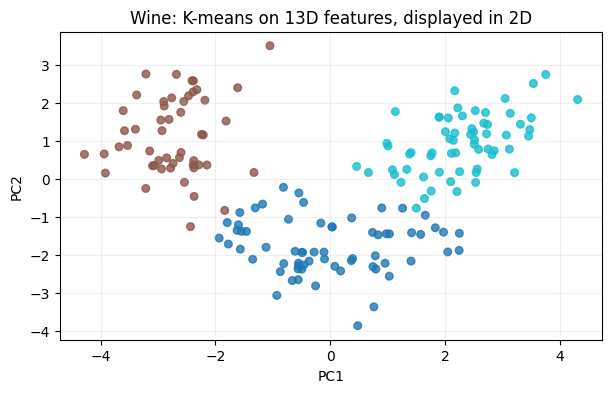

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(projection[:, 0], projection[:, 1], c=cluster_ids, cmap="tab10", s=30, alpha=0.8)
ax.set(xlabel="PC1", ylabel="PC2", title="Wine: K-means on 13D features, displayed in 2D")
ax.grid(alpha=0.2)
plt.show()

Notice the distinction: K-means used **13 standardized features**, while the figure shows **two PCA coordinates**. We cannot read all higher-dimensional cluster distances from a 2D plot.

**Question:** What must change if a user asks for `k=4`? Which lines of the notebook would we have to rerun, and in what order?

---
## 2. Move the numerical work into a function

Open `analysis.py` in your editor. It has two functions:

- `select_features(frame, columns)`: checks the input and returns usable numerical columns;
- `analyze(frame, columns, n_clusters, representation, random_state)`: runs scaling, PCA and K-means and returns the results as a dictionary.

**Important design choice:** `analysis.py` contains **no `streamlit` imports**. This means its calculations can be tested and reused from Jupyter, a command-line script or a future web service.

In [5]:
from analysis import analyze, select_features

checked = select_features(frame, feature_names)
result = analyze(frame, feature_names, n_clusters=3, representation="scaled")

assert checked.shape == (178, 13)
assert result["projection"].shape == (178, 3)  # PC1, PC2, cluster
assert result["counts"].sum() == len(frame)
assert np.array_equal(result["labels"].to_numpy(), cluster_ids)

display(result["counts"].rename_axis("cluster").to_frame())
print("Two displayed PCA axes retain:", f"{result['variance_2d']:.1%}", "of standardized variance")
print("Silhouette:", f"{result['silhouette']:.3f}")

,samples
cluster,
0,65
1,51
2,62


Two displayed PCA axes retain: 55.4% of standardized variance
Silhouette: 0.285


The function is not a class and does not use a database. For this small project, ordinary functions are sufficient.

A key difference from exploratory cells is **the contract**: the caller supplies the data, the feature list and the parameters. The function either returns a predictable structure or raises `ValueError` with an explanation.

### Same samples, different clustering space

Our app offers two ways to run K-means:

- `scaled`: K-means uses all standardized columns; PCA is used only for display.
- `pca2`: K-means uses the first two PCA coordinates.

The experiment connects directly to Practical 9: **changing representation can change the groups**.

In [6]:
scaled_result = analyze(frame, feature_names, n_clusters=3, representation="scaled")
pca2_result = analyze(frame, feature_names, n_clusters=3, representation="pca2")

summary = pd.DataFrame({
    "clustering_space": ["standardized 13D", "PCA 2D"],
    "clusters_found": [len(scaled_result["counts"]), len(pca2_result["counts"])],
    "silhouette_in_own_space": [scaled_result["silhouette"], pca2_result["silhouette"]],
})
display(summary)

agreement = adjusted_rand_score(scaled_result["labels"], pca2_result["labels"])
print("ARI between the two partitions (same observations):", round(agreement, 3))

,clustering_space,clusters_found,silhouette_in_own_space
0,standardized 13D,3,0.284859
1,PCA 2D,3,0.561051


ARI between the two partitions (same observations): 0.932


**Do not rank these representations just by their silhouette values:** silhouette is calculated using a different distance geometry in each case. The ARI above measures agreement **between the two discovered partitions**; it is not an accuracy score against ground-truth classes.

---
## 3. Make wrong input fail clearly

A person using a web application may upload a CSV with missing values, text columns or too few rows. The app should not silently drop rows or produce a misleading chart. It should explain what needs to be fixed.

We start with a clean dataset and deliberately break it.

In [7]:
broken = frame.copy()
broken.loc[0, "alcohol"] = np.nan

try:
    select_features(broken, feature_names)
except ValueError as exc:
    print("Expected validation message:", exc)

Expected validation message:

 Selected features contain missing values; clean the CSV first.


In [8]:
constant_feature = frame.copy()
constant_feature["always_one"] = 1

try:
    select_features(constant_feature, ["alcohol", "always_one"])
except ValueError as exc:
    print("Expected validation message:", exc)

Expected validation message: Remove constant features: always_one


**Why reject a constant feature?** Standardized distance becomes difficult to interpret if a selected feature never changes, and it contributes no useful variation. This teaching example rejects it explicitly rather than silently ignoring it.

The app also rejects more than 5,000 rows to keep classroom exploration responsive; that limit is not a theoretical property of PCA or K-means.

### Regression tests

The project includes `tests/test_analysis.py`. These tests verify expected shapes, repeatable results, invalid input handling and the two possible clustering spaces.

From the project directory, run:

```bash
python -m pytest -q
```

You should see six passing tests before modifying the code. You can rerun the same command after each change.

In [9]:
# A notebook-level smoke test; the same calculation can be called without Streamlit.
again = analyze(frame, feature_names, n_clusters=3, representation="scaled", random_state=42)
assert np.array_equal(result["labels"].to_numpy(), again["labels"].to_numpy())
assert np.isfinite(result["projection"][["PC1", "PC2"]].to_numpy()).all()
print("Repeatability check passed.")

Repeatability check passed.


---
## 4. Add a web interface with Streamlit

The file `app.py` is the **presentation layer**. It reads input, asks for options, calls `analyze()` and displays a figure. It does not contain a second copy of the PCA/K-means implementation.

The essential pattern is simple:

```python
import streamlit as st
from analysis import analyze

k = st.sidebar.slider("Clusters", 2, 8, 3)
# result = analyze(frame, selected_features, n_clusters=k)
st.write("You selected", k, "clusters")
```

With Streamlit's default widget behavior, choosing a new value reruns the app script. **This is not like modifying a notebook variable and hoping all dependent cells are fresh.**

### Run the app locally

In a terminal opened in the extracted project directory:

```bash
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

Open the local URL printed in the terminal (usually `http://localhost:8501`). Streamlit keeps running until you stop it with `Ctrl+C`. We do not launch the server from this notebook because it is a separate application process.

Try this sequence in the browser:

1. Leave the supplied Wine CSV selected. Change `k` from 3 to 4.
2. Switch between **All standardized features** and **First two PCA components**.
3. Upload `data/invalid_example.csv` and read the resulting error message.
4. Return to the default dataset and download the clustered CSV.

The downloaded file has the **original feature columns plus one new `cluster` column**; cluster IDs are arbitrary integers, not cultivar labels.

In [10]:
# Inspect the application as a Python file without trying to start its server.
app_source = Path("app.py").read_text(encoding="utf-8")
compile(app_source, "app.py", "exec")

for required in ["file_uploader", "multiselect", "radio(", "st.pyplot", "download_button", "from analysis import analyze"]:
    assert required in app_source, f"UI is missing: {required}"
print("Application source is syntactically valid and uses the shared analysis function.")

Application source is syntactically valid and uses the shared analysis function.


### How the pieces fit together

| File | Responsibility | What it should *not* do |
|---|---|---|
| `data/wine_features.csv` | Provide a reproducible example input | Pretend to be an external live feed |
| `analysis.py` | Validate features, scale, run PCA and K-means | Display Streamlit widgets |
| `app.py` | Read input, control parameters, show charts and downloads | Duplicate the numerical algorithm |
| `tests/test_analysis.py` | Check the numerical contract and edge cases | Depend on a running browser |
| `requirements.txt` | Declare installation requirements | Store mutable analysis results |

There is a small optimization in `app.py`: `@st.cache_data` caches loading the **unchanging example CSV**. We deliberately keep the first version simple and do not cache clustering results.

---
## 5. Your turn

### Exercise A — expose the cluster sizes (about 7 minutes)

`app.py` already prints cluster sizes as a table. Add a **bar chart** just below that table using Streamlit. You can use `st.bar_chart` with `result["counts"]`.

Check that the bar chart updates when you change `k`. Do not hard-code three bars.

In [11]:
# Quick notebook sketch: a Series of cluster sizes that you can send to the UI.
counts = result["counts"]
print("Cluster IDs and counts:")
display(counts.rename_axis("cluster").to_frame())

# Your solution starts here: optionally sketch how to highlight a cluster with < 10% of rows.

Cluster IDs and counts:


,samples
cluster,
0,65
1,51
2,62


### Exercise B — handle an invalid upload (about 8 minutes)

Use the supplied `data/invalid_example.csv` in the browser. This file is derived from the first 20 real Wine samples and deliberately contains one missing measurement.

The expected behavior is a **readable error message**, not a traceback or a silently modified dataset. Explain in one or two sentences why dropping missing rows automatically might change the sample under analysis.

If the app worked as expected, find the relevant check in `analysis.py` and the corresponding error display in `app.py`.

In [12]:
invalid = pd.read_csv("data/invalid_example.csv")
print("Invalid fixture shape:", invalid.shape)
print("Missing cells:", int(invalid.isna().sum().sum()))
assert int(invalid.isna().sum().sum()) == 1

# Your solution starts here: try calling select_features() in a try/except block.

Invalid fixture shape: (20, 13)
Missing cells: 1


### Exit challenge — short discussion

Suppose we ask you to add DBSCAN to this application next week.

1. Where should the `DBSCAN` import and `.fit_predict()` call go: `app.py` or `analysis.py`? Why?
2. Which new controls would be useful in the UI?
3. Why is a repeatable `random_state` useful when someone reports a bug?
4. What would you need to change before uploading private or very large datasets to a public hosted version?

There is no need to implement DBSCAN today.

---
## 6. Optional extension (15 minutes)

Pick **one** improvement:

- **Small-cluster warning.** Show `st.warning(...)` if any cluster contains fewer than 10% of observations. Keep the fraction calculation in `analysis.py` or a separate pure helper; keep message display in `app.py`.
- **Add a test.** Test that a non-numerical column and an invalid cluster count produce useful errors, then run `python -m pytest -q`.
- **Extra UI control.** Add a checkbox that shows or hides the raw CSV preview. Verify it changes only the presentation, not cluster assignments.

Do not deploy the app publicly during this exercise: the goal is a reproducible local POC.

### What this practical prepares you for

In **Lab 04**, you will build your own small MVP/POC. The exact data and task may be different, but the engineering pattern stays the same:

**defined input → validation → reusable processing → visible result → reproducible run instructions.**

Useful official references:

- [Streamlit: basic concepts](https://docs.streamlit.io/get-started/fundamentals/main-concepts)
- [Streamlit: widget behavior](https://docs.streamlit.io/develop/concepts/architecture/widget-behavior)
- [Streamlit: AppTest](https://docs.streamlit.io/develop/api-reference/app-testing/st.testing.v1.apptest)